# Heart Disease Prediction

**Problem:** From 13 clinical measurements (age, chest-pain type, cholesterol, max heart rate…), predict whether a patient shows signs of heart disease.

**Dataset:** UCI Heart Disease (Cleveland) — **303 patients**, the most widely used heart-disease dataset in ML education. *Educational project — not a medical tool.*

**Approach:** clean the UCI file (missing values marked `?`), binarize the diagnosis, compare Logistic Regression and Random Forest.

In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
df = pd.read_csv(URL, names=cols, na_values="?")
print("Patients:", df.shape)
df = df.fillna(df.median(numeric_only=True))
df["disease"] = (df["num"] > 0).astype(int)
print(df["disease"].value_counts().rename({0: "no disease", 1: "disease"}))
X = df.drop(columns=["num", "disease"]); y = df["disease"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

Patients: (303, 14)
disease
no disease    164
disease       139
Name: count, dtype: int64


Logistic Regression accuracy: 0.8684
Random Forest accuracy: 0.8684
              precision    recall  f1-score   support

  No disease      0.919     0.829     0.872        41
     Disease      0.821     0.914     0.865        35

    accuracy                          0.868        76
   macro avg      0.870     0.872     0.868        76
weighted avg      0.874     0.868     0.869        76



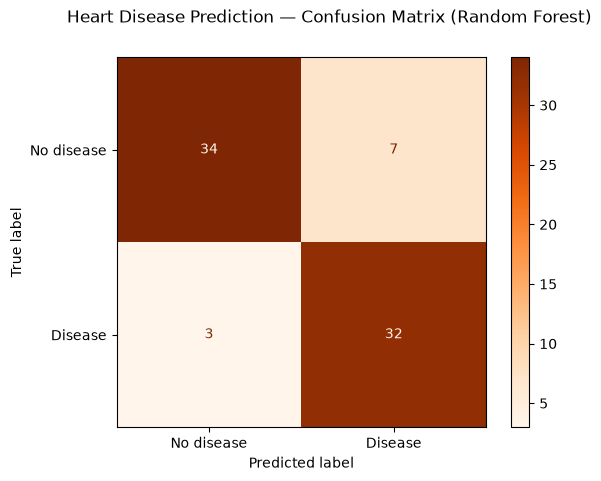

In [2]:
sc = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=5000).fit(sc.transform(X_tr), y_tr)
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_tr, y_tr)
for name, p in [("Logistic Regression", lr.predict(sc.transform(X_te))), ("Random Forest", rf.predict(X_te))]:
    print(name, "accuracy:", round(accuracy_score(y_te, p), 4))
print(classification_report(y_te, rf.predict(X_te), target_names=["No disease", "Disease"], digits=3))
disp = ConfusionMatrixDisplay.from_predictions(y_te, rf.predict(X_te), display_labels=["No disease", "Disease"], cmap="Oranges")
disp.figure_.suptitle("Heart Disease Prediction — Confusion Matrix (Random Forest)")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

## Result
On only 303 patients, both models scored **86.8% accuracy** — small medical datasets are noisy, and honest reporting matters more here than a big headline number. A model like this is a screening aid at best, never a diagnosis.